# Final figures

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seafloor as sf

SHIP, SAT, THIRD, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
ALT1, ALT2 = "#4a3aa7", "#1baf7a"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "lines.linewidth": 2, "legend.frameon": False, "figure.facecolor": "white"})
OUT = sf.FIG_DIR / "final"; OUT.mkdir(exist_ok=True)

lon, lat, z, ship, dx, dy = sf.load_clean()
extent = [lon[0], lon[-1], lat[0], lat[-1]]; aspect = 1 / np.cos(np.deg2rad(lat.mean()))
zf = np.where(np.isnan(z), np.nanmedian(z), z)
rng = np.random.default_rng(0)

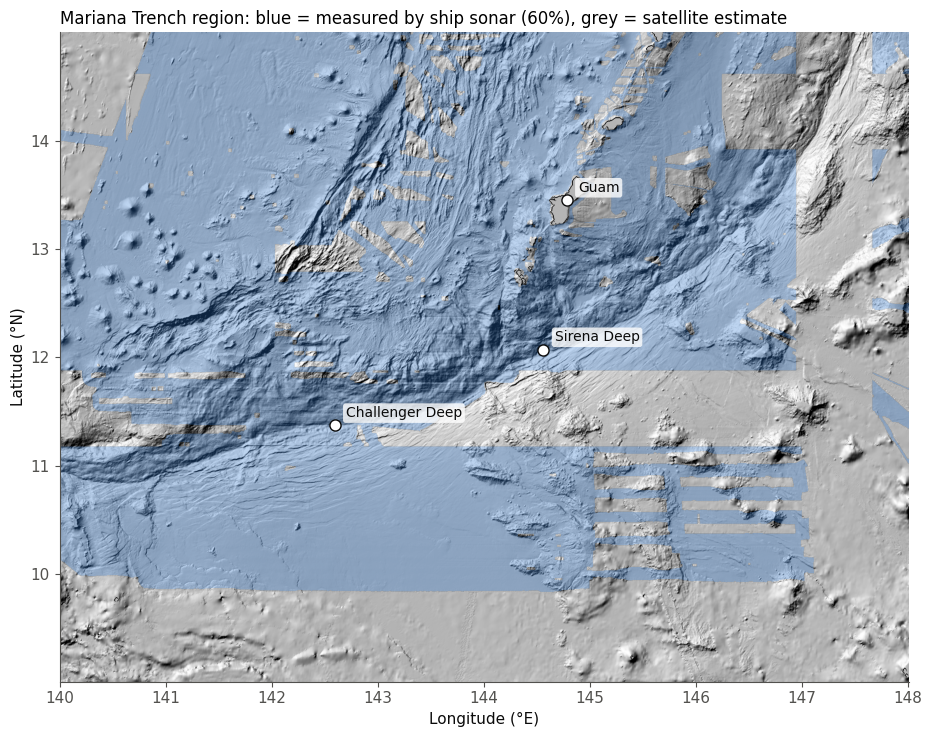

In [2]:
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.grid(False)
ax.imshow(sf.hillshade(zf, dx, dy), extent=extent, origin="lower", cmap="gray", aspect=aspect)
ax.imshow(np.where(ship, 1, np.nan), extent=extent, origin="lower", cmap=ListedColormap([SHIP]), alpha=0.30, aspect=aspect)
for name, (la, lo) in {"Challenger Deep": (11.37, 142.59), "Sirena Deep": (12.07, 144.56), "Guam": (13.45, 144.78)}.items():
    ax.plot(lo, la, "o", ms=8, mfc="white", mec=INK); ax.annotate(name, (lo, la), xytext=(8, 6), textcoords="offset points", color=INK, fontsize=10,
                                                               bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)")
ax.set_title(f"Mariana Trench region: blue = measured by ship sonar ({ship[~np.isnan(z)].mean():.0%}), grey = satellite estimate", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(OUT / "fig1_study_area.png", dpi=250); plt.show()

/tmp/ipykernel_708/712358786.py:7: RuntimeWarning: invalid value encountered in cast
  db = np.floor(depth / band_m).astype(int)


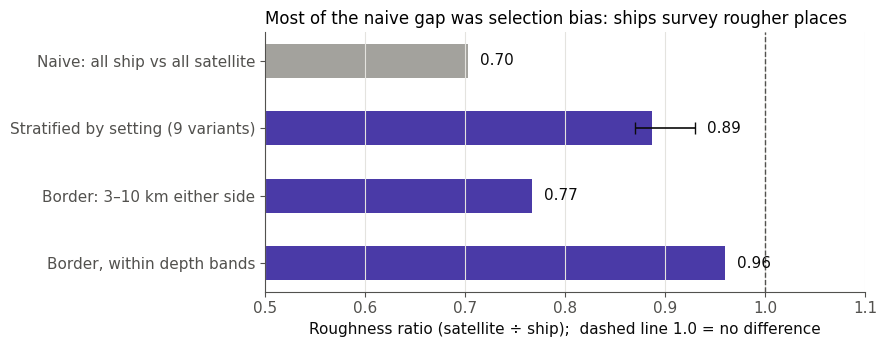

naive 0.70 | stratified 0.87–0.93 | border 0.77 | border+depth 0.96


In [3]:
from scipy import ndimage
F = sf.compute_features(z, dx, dy); rough, depth, bpi_b = F[..., 2], F[..., 0], F[..., 4]
ok = ~np.isnan(F).any(-1); DX = float(np.mean(dx))
ratio = lambda a, b: np.median(b) / np.median(a)
naive = ratio(rough[ok & ship], rough[ok & ~ship])
def strat(band_m=500, n_bpi=3, cells=ok):
    db = np.floor(depth / band_m).astype(int)
    bb = np.digitize(bpi_b, np.nanpercentile(bpi_b[ok], np.linspace(0, 100, n_bpi + 1)[1:-1]))
    st = db * 100 + bb; rows = []
    for s in np.unique(st[cells]):
        m = cells & (st == s); a, b = rough[m & ship], rough[m & ~ship]
        if len(a) >= 300 and len(b) >= 300: rows.append((len(a) + len(b), ratio(a, b)))
    rows = np.array(rows); return np.exp(np.average(np.log(rows[:, 1]), weights=rows[:, 0]))
strat_vals = [strat(b, n) for b in (250, 500, 1000) for n in (2, 3, 5)]
d_in = ndimage.distance_transform_edt(ship) * DX / 1000; d_out = ndimage.distance_transform_edt(~ship) * DX / 1000
border_cells = ok & (((d_in >= 3) & (d_in <= 10) & ship) | ((d_out >= 3) & (d_out <= 10) & ~ship))
border = ratio(rough[border_cells & ship], rough[border_cells & ~ship])
border_depth = strat(500, 1, border_cells)

labels = ["Naive: all ship vs all satellite", "Stratified by setting (9 variants)", "Border: 3–10 km either side", "Border, within depth bands"]
vals = [naive, np.median(strat_vals), border, border_depth]
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(labels))[::-1]
ax.barh(y, vals, height=0.5, color=["#a3a29d", ALT1, ALT1, ALT1])
ax.errorbar([np.median(strat_vals)], [y[1]], xerr=[[np.median(strat_vals) - min(strat_vals)], [max(strat_vals) - np.median(strat_vals)]], fmt="none", ecolor=INK, capsize=4, lw=1.2)
ends = [naive, max(strat_vals), border, border_depth]
for yy, v, e in zip(y, vals, ends): ax.text(e + 0.012, yy, f"{v:.2f}", va="center", color=INK)
ax.axvline(1, color=INK2, lw=1, ls="--")
ax.set_yticks(y, labels); ax.set_xlim(0.5, 1.1); ax.grid(axis="y", visible=False)
ax.set_xlabel("Roughness ratio (satellite ÷ ship);  dashed line 1.0 = no difference")
ax.set_title("Most of the naive gap was selection bias: ships survey rougher places", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(OUT / "fig2_selection_bias.png", dpi=250); plt.show()
print(f"naive {naive:.2f} | stratified {min(strat_vals):.2f}–{max(strat_vals):.2f} | border {border:.2f} | border+depth {border_depth:.2f}")

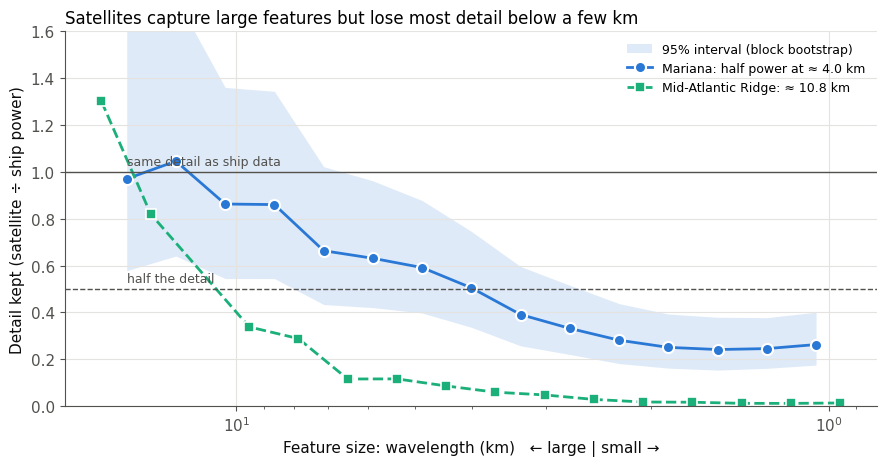

In [4]:
wl, A, B, _ = sf.block_spectra(z, ship, dx, dy)
R = np.exp(B.mean(0) - A.mean(0))
boot = np.array([np.exp(B[rng.integers(0, len(B), len(B))].mean(0) - A[rng.integers(0, len(A), len(A))].mean(0)) for _ in range(1000)])
lo_, hi_ = np.percentile(boot, [2.5, 97.5], axis=0)
hp = sf.half_power_wavelength(wl, A, B)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.fill_between(wl, lo_, hi_, color=SHIP, alpha=0.15, lw=0, label="95% interval (block bootstrap)")
ax.semilogx(wl, R, "o-", color=SHIP, ms=8, mec="white", mew=1.5, label=f"Mariana: half power at ≈ {hp:.1f} km")
extra = sf.DATA_DIR / "10_curves.json"
if extra.exists():
    for (name, cv), col in zip([(k, v) for k, v in json.load(open(extra)).items() if not k.startswith("Mariana")], [THIRD, "#4a3aa7"]):
        ax.semilogx(cv["wl"], cv["R"], "s--", color=col, ms=7, mec="white", mew=1.2, label=f"{name}: ≈ {cv['hp']:.1f} km")
ax.axhline(1, color=INK2, lw=1); ax.axhline(0.5, color=INK2, lw=1, ls="--")
ax.text(wl.max(), 1.03, "same detail as ship data", color=INK2, fontsize=9, ha="left")
ax.text(wl.max(), 0.53, "half the detail", color=INK2, fontsize=9, ha="left")
ax.invert_xaxis(); ax.set_ylim(0, 1.6)
ax.set(xlabel="Feature size: wavelength (km)   ← large | small →", ylabel="Detail kept (satellite ÷ ship power)")
ax.set_title("Satellites capture large features but lose most detail below a few km", loc="left", fontsize=12)
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "fig3_spectrum.png", dpi=250); plt.show()

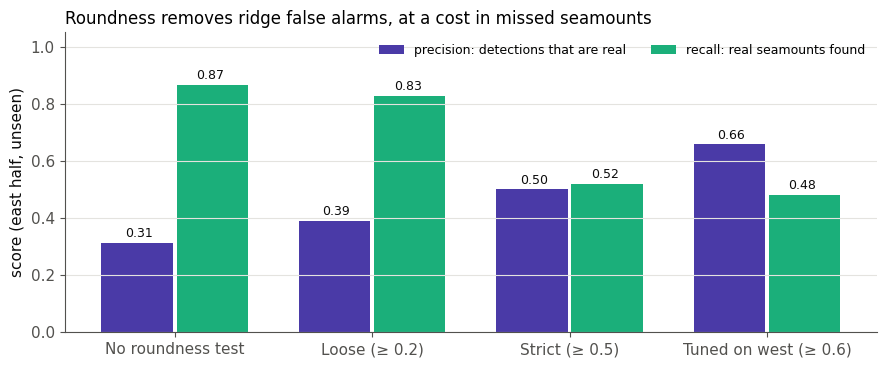

In [5]:
d = sf.detect_peaks(z, dx, dy, lat, lon); cat = sf.load_catalog(lon, lat)
east_d, east_c = d["lon"] >= 144, cat["lon"] >= 144
def sc(h, r):
    k = east_d & (d["h"] >= h) & (d["round"] >= r)
    dm, cm = sf.match(d["lat"][k], d["lon"][k], cat["lat"][east_c], cat["lon"][east_c]); return dm.mean(), cm.mean()
opts = {"No roundness test": (1100, 0.0), "Loose (≥ 0.2)": (1100, 0.2), "Strict (≥ 0.5)": (1100, 0.5), "Tuned on west (≥ 0.6)": (1100, 0.6)}
res = {k: sc(*v) for k, v in opts.items()}
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(res)); w = 0.36
P = [v[0] for v in res.values()]; Rc = [v[1] for v in res.values()]
ax.bar(x - w / 2 - 0.01, P, w, color=ALT1, label="precision: detections that are real")
ax.bar(x + w / 2 + 0.01, Rc, w, color=ALT2, label="recall: real seamounts found")
for xx, p, r in zip(x, P, Rc):
    ax.text(xx - w / 2, p + 0.02, f"{p:.2f}", ha="center", fontsize=9, color=INK); ax.text(xx + w / 2, r + 0.02, f"{r:.2f}", ha="center", fontsize=9, color=INK)
ax.set_xticks(x, list(res)); ax.set_ylim(0, 1.05); ax.grid(axis="x", visible=False); ax.set_ylabel("score (east half, unseen)")
ax.set_title("Roundness removes ridge false alarms, at a cost in missed seamounts", loc="left", fontsize=12)
ax.legend(loc="upper right", fontsize=9, ncol=2)
fig.tight_layout(); fig.savefig(OUT / "fig4_detector.png", dpi=250); plt.show()

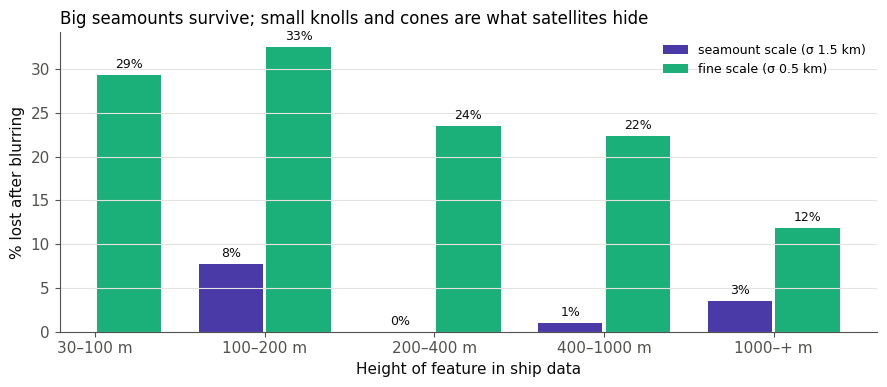

In [6]:
p = sf.DATA_DIR / "11_loss.json"
if p.exists():
    tables = {k: np.array(v) for k, v in json.load(open(p)).items()}
    all_bins = sorted({(a, b) for t in tables.values() for a, b in t[:, :2]})
    fig, ax = plt.subplots(figsize=(9, 4))
    w = 0.38
    for k, ((name, t), col) in enumerate(zip(tables.items(), [ALT1, ALT2])):
        idx = np.array([all_bins.index((a, b)) for a, b in t[:, :2]])
        ax.bar(idx + (k - 0.5) * (w + 0.02), t[:, 3] * 100, w, color=col, label=name)
        for xx, v in zip(idx + (k - 0.5) * (w + 0.02), t[:, 3] * 100): ax.text(xx, v + 0.8, f"{v:.0f}%", ha="center", fontsize=9, color=INK)
    ax.set_xticks(range(len(all_bins)), [f"{int(a)}–{int(b) if b < 1e8 else '+'} m" for a, b in all_bins])
    ax.grid(axis="x", visible=False); ax.set(xlabel="Height of feature in ship data", ylabel="% lost after blurring")
    ax.set_title("Big seamounts survive; small knolls and cones are what satellites hide", loc="left", fontsize=12)
    ax.legend(fontsize=9); fig.tight_layout(); fig.savefig(OUT / "fig5_what_is_lost.png", dpi=250); plt.show()
else:
    print("Run 11_blurring_experiment first (it saves data/11_loss.json).")